# Acquisition Function Output Analysis

Load a saved active-learning `output_dict` HDF5 file and start with the mean test reduced-error plot.

In [1]:
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset
import os
from scipy.ndimage import zoom


# try:
#     get_ipython().run_line_magic("matplotlib", "widget")
# except (ValueError, RuntimeError):
#     get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt


# Make package and notebook-local helper modules importable whether this starts in repo root or notebooks/
repo_root = Path.cwd() if (Path.cwd() / "src" / "nnerror").exists() else Path.cwd().parent.parent
src_root = str((repo_root / "src").resolve())
nb_root = str((repo_root / "notebooks"/"STM").resolve())
for import_root in (src_root, nb_root):
    if import_root not in sys.path:
        sys.path.insert(0, import_root)




from nnerror.networks import FNO_im2spec, CustomDecoder, im2spec, im2spec_attn
from nnerror.networks.custom_nn import CustomCNN
from nnerror.training_functions import err_estimation, train_model, predict_spectra, norm_0to1, predict_posterior, append_training_set, distance_acq_fn
from nnerror.plot_functions import plot_only_training_loss, plot_training_loss, \
    plot_error_prediction, plot_spectra, plot_error_prediction_3d, plot_scale_slider, plot_latent_space, cluster_latent_space, plot_latent_distribution, plot_scale_specific_error_and_acquisition_maps
from nnerror.utils import append_multiscale_data, edges_zeroed_image, interpolated_center_crop, paired_images_spectra_1
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
%matplotlib inline

from pathlib import Path
import re

import h5py
import numpy as np
import matplotlib.pyplot as plt


cwd = Path.cwd()
stm_dir = cwd / "notebooks" / "STM" if (cwd / "notebooks" / "STM").exists() else cwd
results_dir = stm_dir / "data" / "active_learning_results2"

h5_files = sorted(results_dir.glob("*.h5"), key=lambda path: path.stat().st_mtime)
if not h5_files:
    raise FileNotFoundError(f"No .h5 files found in {results_dir}")


# By default, analyze the newest saved acquisition result. Replace this with
# a specific Path(...) if you want to load a different run.
output_file = h5_files[-1]
output_file



error_type = "L1"  # "L1", "L2", or "cos"
acquisition_iterations = 50
num_new_points = 5
scale_type = "ms"  # "ms" or "ss"
norm_type = "normgauss"
mask_suffix = "_mask" if scale_type == "ms" else ""  # --mask-channel is only used for ms + pad
output_file = results_dir / (
    f"al_im2spec_{error_type}_WS32_latent5_appendpad_"
    f"{acquisition_iterations}iters_{num_new_points}pts_"
    f"distanceacq_{scale_type}_{norm_type}{mask_suffix}.h5"
)
print(output_file)

/home/cloud/nfs_share/vm_dir/NN_Error/notebooks/STM/data/active_learning_results2/al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask.h5


In [3]:
def plot_reduced_errors_and_scales(errors, coords_reduced, aq_indices=None):
    xs = coords_reduced[:, 0]
    ys = coords_reduced[:, 1]
    scales = coords_reduced[:, 2]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sc0 = axes[0].scatter(xs, ys, c=errors, s=80)
    axes[0].set_title("Reduced Minimum Errors, mean = {:.3f}".format(np.mean(errors)))
    axes[0].set_xlabel("x")
    axes[0].set_ylabel("y")
    axes[0].set_aspect("equal")
    plt.colorbar(sc0, ax=axes[0], label="Minimum Error")

    sc1 = axes[1].scatter(xs, ys, c=scales, s=80)
    axes[1].set_title("Best Scale at Each (x, y)")
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("y")
    axes[1].set_aspect("equal")
    plt.colorbar(sc1, ax=axes[1], label="Best Scale")

    if aq_indices is not None and len(aq_indices) > 0:
        aq_indices = np.asarray(aq_indices, dtype=int)

        axes[0].scatter(
            xs[aq_indices],
            ys[aq_indices],
            marker="x",
            s=120,
            linewidths=2,
            label="Acquisition points",
        )
        axes[0].legend()

    plt.tight_layout()
    plt.show()


def load_h5_ragged(filename):
    data_dict = {}

    with h5py.File(filename, "r") as f:
        for key in f.keys():
            group = f[key]

            values = []
            for i in range(len(group)):
                values.append(group[str(i)][()])

            data_dict[key] = values

    return data_dict


def infer_num_new_points(output_dict, output_file, fallback=5):
    match = re.search(r"_(\d+)pts_", output_file.name)
    if match:
        return int(match.group(1))

    train_indices = output_dict.get("train_indices", [])
    if len(train_indices) > 1:
        return int(len(train_indices[1]) - len(train_indices[0]))

    return fallback



In [4]:

output_dict = load_h5_ragged(output_file)
{key: len(value) for key, value in output_dict.items()}

{'im2spec_test_mismatches': 50,
 'pred_error_test': 50,
 'predicted_errors_all': 50,
 'reduced_coords': 50,
 'reduced_errors': 50,
 'reduced_errors_im2spec': 50,
 'test_indices': 50,
 'train_indices': 50}

(347,)
245
[ 930  863  188  949  981  762  956  761  891  892  159  885  886  857
  117  184  127  158  828   88  980  953  987  628  124  183  118  213
  688  471  893  734  694  951  764  119  757  662  984  952  853  982
  889  190  890  314  884  925  568  914 1017 1018  990 1014  991  404
  246  920  486  278 1012  532  126  181 1010 1022 1019 1021  733 1020
  125   56   62   22 1015  691  796  533  917  854  792  582  723  659
  698  760  221  537  918  703   29  954  472  470  959  895  441  540
  728  671   84  756  116  768  223  581  921  325  693 1013   30  215
  120 1023  868  926  988  927  989  725   63   90  222   25  609  697
  696  799  858  735   86  535  824  950  473  859  758  791   61  829
  826  631  567  284  569  948  156  823  794  765  861  253  255  501
   18  789  727  726  724  790  667  670  825  822  630  692  505  665
  629  599  285  633  763  634  538  919  788  632  664  602  597  701
  157  409  660  247  539  820  852  916  827 1011  979  783  151 

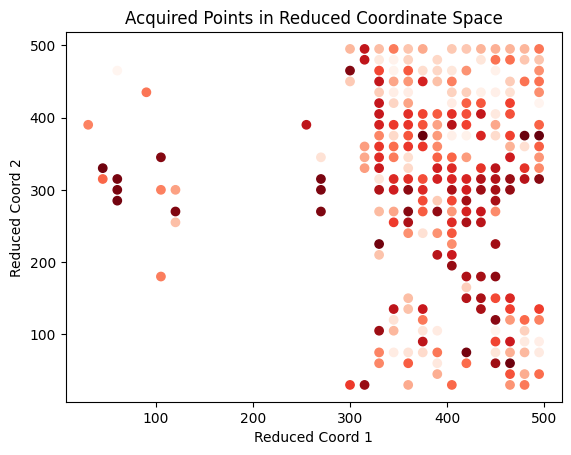

In [5]:
train_indices = output_dict.get("train_indices")

acquired_indices = [ind for ind in train_indices[-1] if ind not in train_indices[0]]

print(train_indices[-1].shape)
print(len(acquired_indices))

acquired_indices = np.array(acquired_indices)
print(acquired_indices)
acq_coords = output_dict["reduced_coords"][-1][acquired_indices]
# print(acq_coords.shape)
# print(acq_coords)
fig, ax = plt.subplots()
ax.scatter(acq_coords[:, 0], acq_coords[:, 1], c=np.arange(len(acq_coords)),  cmap = 'Reds', marker="o")
ax.set_xlabel("Reduced Coord 1")
ax.set_ylabel("Reduced Coord 2")
ax.set_title("Acquired Points in Reduced Coordinate Space")
plt.show()

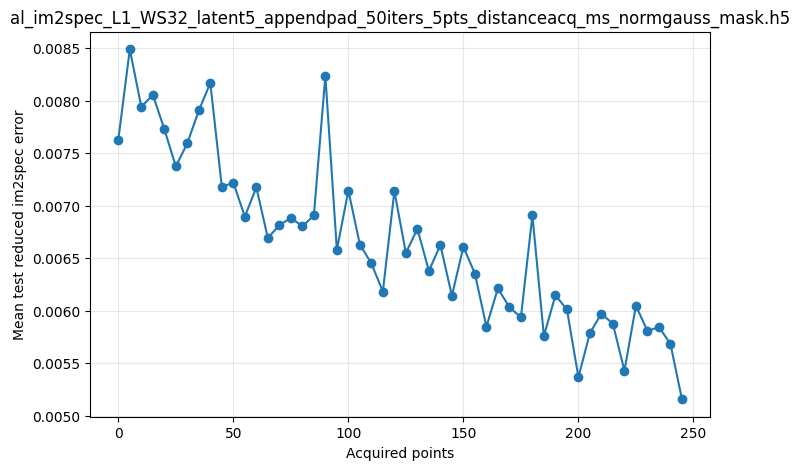

In [6]:


train_indices_arr = output_dict["train_indices"]
test_indices_arr = [indices.astype(int) for indices in output_dict["test_indices"]]
reduced_errors_arr = np.array(output_dict["reduced_errors_im2spec"])

num_saved_iterations = len(reduced_errors_arr)
points_per_iteration = infer_num_new_points(output_dict, output_file)

test_reduced_errors = [
    reduced_errors_arr[i][test_indices_arr[i]]
    for i in range(num_saved_iterations)
]

mean_test_reduced_errors = [
    np.mean(test_reduced_errors[i])
    for i in range(num_saved_iterations)
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    np.arange(num_saved_iterations) * points_per_iteration,
    mean_test_reduced_errors,
    marker="o",
)
ax.set_xlabel("Acquired points")
ax.set_ylabel("Mean test reduced im2spec error")
ax.set_title(Path(output_file).name)
ax.grid(True, alpha=0.3)
plt.show()

In [7]:
output_file

PosixPath('/home/cloud/nfs_share/vm_dir/NN_Error/notebooks/STM/data/active_learning_results2/al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask.h5')

# Set plot_iteration

In [8]:
plot_iteration = 1

Plotting iteration 1 from al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask.h5


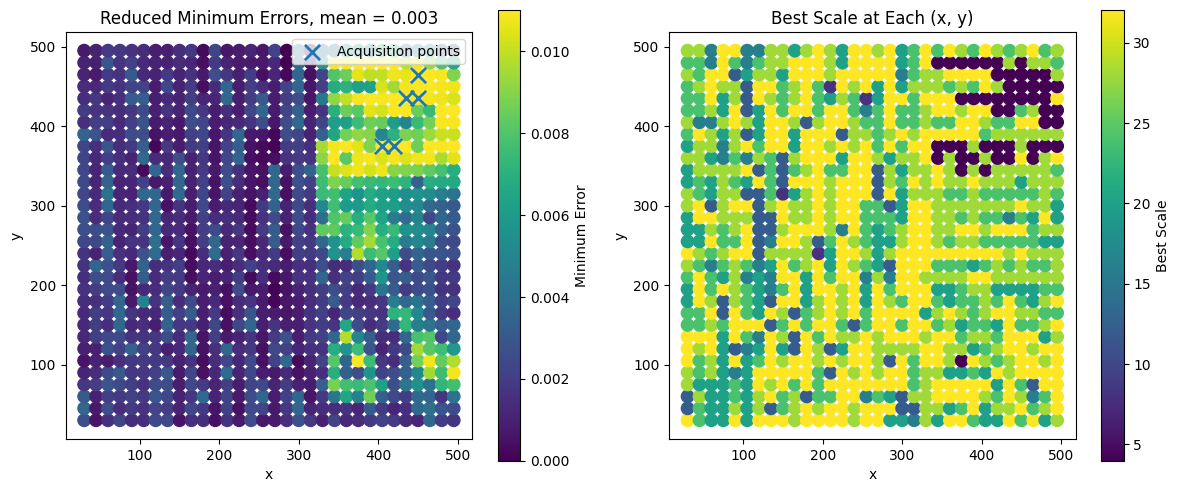

In [9]:

error_key = "reduced_errors"

if "reduced_coords" not in output_dict:
    raise KeyError(
        "This output file does not contain reduced_coords. "
        "Re-run stm_ms_acqfn_script.py after the reduced_coords save change."
    )

reduced_errors_to_plot = np.asarray(output_dict[error_key][plot_iteration])
reduced_coords_to_plot = np.asarray(output_dict["reduced_coords"][plot_iteration])
train_idx_iter = np.asarray(output_dict["train_indices"][plot_iteration])




aq_ind, _ = distance_acq_fn(
    reduced_errors_to_plot,
    beta=1,
    lambda_=1,
    sample_next_points=5,
    exclude_indices=train_idx_iter,
)

print(f"Plotting iteration {plot_iteration} from {Path(output_file).name}")
plot_reduced_errors_and_scales(reduced_errors_to_plot, reduced_coords_to_plot, aq_indices = aq_ind)

## confirm that the next set of aq_ind are used by the program 

In [10]:
print(aq_ind)
next_iteration = plot_iteration + 1
train_idx_next_iter = np.asarray(output_dict["train_indices"][next_iteration])
print(train_idx_next_iter[-5:])


# These are the coords that it samples.
print(reduced_coords_to_plot[aq_ind, :2])



[762 956 761 891 892]
[762 956 761 891 892]
[[420. 375.]
 [450. 465.]
 [405. 375.]
 [435. 435.]
 [450. 435.]]


# Get original data

In [11]:
from stm_utils import Sxm_Image
from CITS_Class import CITS_Analysis
def running_on_colab():
    return False

In [12]:
data_folder = r"data/large_area" if not running_on_colab() else r"notebooks/STM/data/large_area"

img_sxm = os.path.join(data_folder, "EnZn2As2017.sxm")
spectra_sxm = os.path.join(data_folder, "EuZn2As2003.3ds")
#Get the morphology image
full_image = Sxm_Image(img_sxm).image()
full_image = norm_0to1(full_image)

#Get the current spectra
cits_obj = CITS_Analysis(spectra_sxm)
hyperspectra = cits_obj.current

full_image.shape, hyperspectra.shape

File import successful.


((512, 512), (80, 250, 121))

In [13]:
WS = 32
WS_init = 4
d_WS = 4
n_epochs_im2spec = 200
n_epochs_error = 200
error_type = "cos" # "L1", "L2", or "cos"
model_type = 'im2spec'
append_image_type = "pad" if model_type == 'im2spec' or 'im2spec_attn' or 'CustomCNN' else "interpolate" #pad, interpolate
use_swa = True
latent_dim = 5
last_swa_epochs = 100

(1024, 32, 32) (1024, 121) (1024, 2)
[30. 30.]


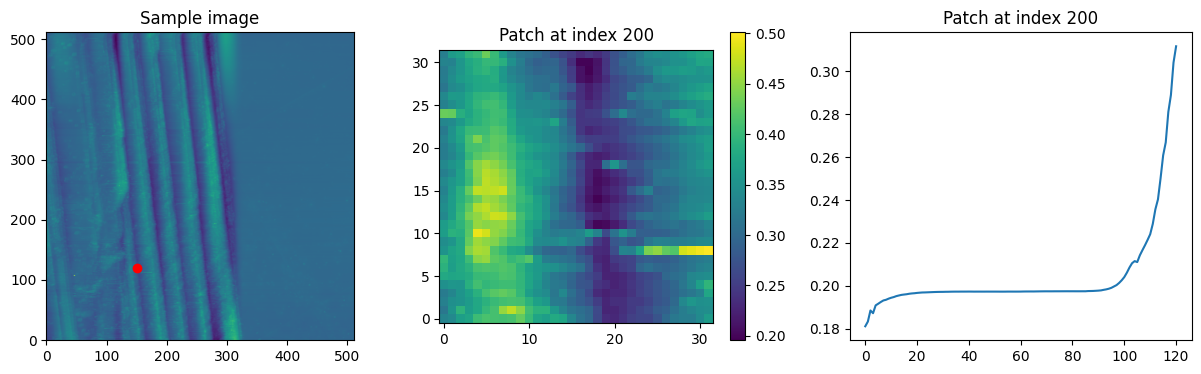

In [14]:


images, spectra, coordinates = paired_images_spectra_1(full_image, cits_obj, hyperspectra, window_size = WS,
                                                       coordinate_step = 15, image_norm=False, spectra_norm = False)

print(images.shape, spectra.shape, coordinates.shape)

print(coordinates[0])
fig, ax = plt.subplots(1, 3, figsize = (15, 4))


idx = 200

ax[0].imshow(full_image, origin = 'lower')
ax[0].scatter(coordinates[idx, 1], coordinates[idx, 0], c ="r")
ax[0].set_title("Sample image")


im = ax[1].imshow(images[idx], origin = 'lower')
fig.colorbar(im, ax=ax[1])
ax[1].set_title(f"Patch at index {idx}")
ax[2].plot(spectra[idx])
ax[2].set_title(f"Patch at index {idx}")

plt.show()

In [15]:
# coordinates are reversed.
swap_coordinates = coordinates.copy()
swap_coordinates = swap_coordinates[:, [1, 0]]
swap_coordinates.shape

(1024, 2)

In [16]:
images_all = images.copy()
spectra_all = spectra.copy()
swap_coordinates_all = swap_coordinates.copy()
#print(swap_coordinates_all[aq_ind])

In [17]:
images, spectra, scale_coordinates = append_multiscale_data(images_all, spectra_all, scales=np.arange(WS_init, WS, d_WS),
                                                            coordinates=swap_coordinates_all,
                                                            append_image_type=append_image_type)

Augmented images shape: (8192, 32, 32), Augmented spectra shape: (8192, 121), Augmented coordinates shape: (8192, 3)


# Plot 3D

In [18]:
predicted_errors = output_dict['predicted_errors_all'][plot_iteration]



In [19]:
import numpy as np
from nnerror.training_functions import distance_acq_fn


plot_aq_ind, plot_aq_fn = distance_acq_fn(predicted_errors,
                                        beta=1,
                                        lambda_=1,
                                        sample_next_points=10,
                                        exclude_indices=[])

print("Shape of plot_aq_fn:", plot_aq_fn.shape)
print("Shape of plot_aq_ind:", plot_aq_ind.shape)

Shape of plot_aq_fn: (8192,)
Shape of plot_aq_ind: (10,)


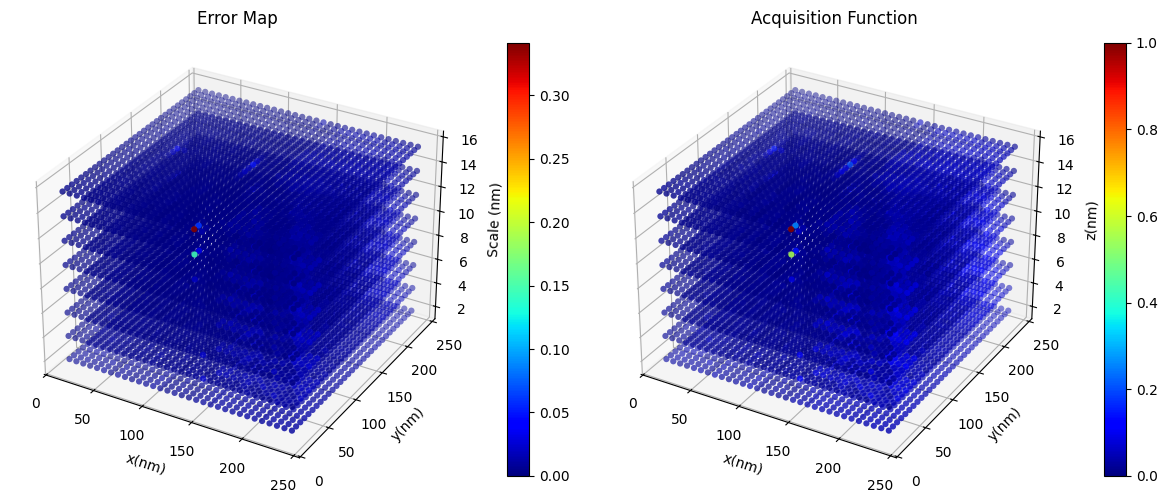

In [20]:
plot_error_prediction_3d(predicted_errors.reshape(-1,1), plot_aq_fn, scale_coordinates, plot_aq_ind, alpha_scale = False, colormap = 'jet')

# Visualize spatial coords

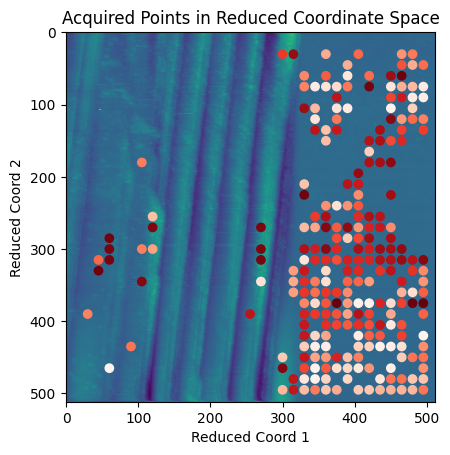

In [21]:
train_indices = output_dict.get("train_indices")

acquired_indices = [ind for ind in train_indices[-1] if ind not in train_indices[0]]

# print(train_indices[-1].shape)
# print(len(acquired_indices))

acquired_indices = np.array(acquired_indices)
# print(acquired_indices)
acq_coords = output_dict["reduced_coords"][-1][acquired_indices]
# print(acq_coords.shape)
# print(acq_coords)
fig, ax = plt.subplots()
ax.imshow(full_image)
ax.scatter(acq_coords[:, 0], acq_coords[:, 1], c=np.arange(len(acq_coords)),  cmap = 'Reds', marker="o")
ax.set_xlabel("Reduced Coord 1")
ax.set_ylabel("Reduced Coord 2")
ax.set_title("Acquired Points in Reduced Coordinate Space")
plt.show()

# Corrected reduction (patch order)

The original `reduce_errors_and_coords` sorted the reduced rows by the swapped `(x, y)` coordinates,
which is column-major order, while patch indices (`original_indices`, `train_indices`) are row-major.
This version groups by patch index instead, so position `i` of the reduced arrays is patch `i`.
`scale_coordinates` stacks one block of `N` patches per scale, so `patch = row % N`.

In [22]:
import pandas as pd


def reduce_errors_and_coords_fixed(predicted_errors, scale_coordinates, n_patches):
    """Minimum error over scales for each patch, returned in patch-index order."""
    predicted_errors = np.asarray(predicted_errors).reshape(-1)
    assert len(predicted_errors) == len(scale_coordinates)
    assert len(predicted_errors) % n_patches == 0

    df_errors = pd.DataFrame({
        "x": scale_coordinates[:, 0],
        "y": scale_coordinates[:, 1],
        "scale": scale_coordinates[:, 2],
        "error": predicted_errors,
        "patch": np.arange(len(predicted_errors)) % n_patches,
    })

    reduced = (
        df_errors.loc[df_errors.groupby("patch")["error"].idxmin()]
        .sort_values("patch")
        .reset_index(drop=True)
    )

    errors = reduced["error"].to_numpy()
    coords_reduced = reduced[["x", "y", "scale"]].to_numpy()

    return errors, coords_reduced

coords match patch order: True
same values as saved reduced_errors (up to order): True
Plotting corrected reduction for iteration 1


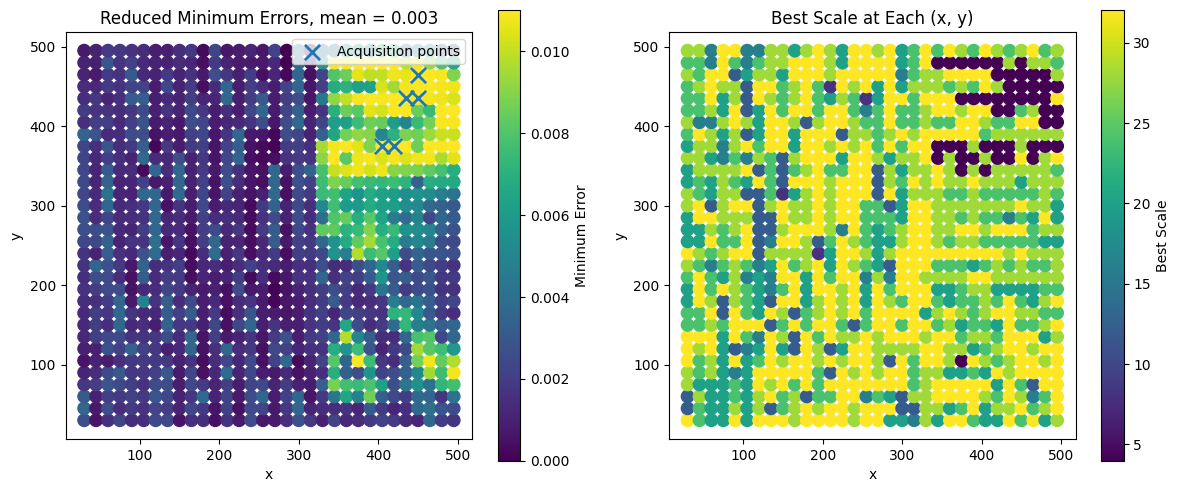

In [23]:
n_patches = len(images_all)

reduced_errors_fixed, reduced_coords_fixed = reduce_errors_and_coords_fixed(
    predicted_errors, scale_coordinates, n_patches
)

# Sanity checks: rows are now in patch order, and the values are the same set as the saved (old-order) ones.
print("coords match patch order:", np.allclose(reduced_coords_fixed[:, :2], swap_coordinates_all))
print("same values as saved reduced_errors (up to order):",
      np.allclose(np.sort(reduced_errors_fixed), np.sort(np.asarray(output_dict["reduced_errors"][plot_iteration]))))

# Acquisition with the corrected order: aq indices are now patch indices.
train_idx_iter = np.asarray(output_dict["train_indices"][plot_iteration], dtype=int)
aq_ind_fixed, _ = distance_acq_fn(
    reduced_errors_fixed,
    beta=1,
    lambda_=1,
    sample_next_points=points_per_iteration,
    exclude_indices=train_idx_iter,
)

print(f"Plotting corrected reduction for iteration {plot_iteration}")
plot_reduced_errors_and_scales(reduced_errors_fixed, reduced_coords_fixed, aq_indices=aq_ind_fixed)

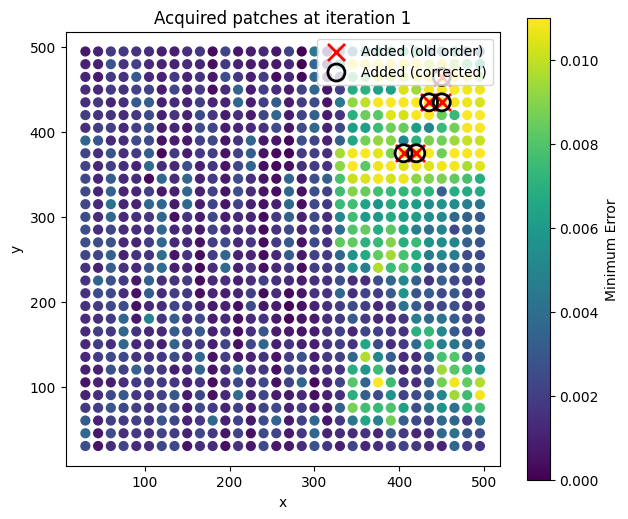

In [24]:
# Old vs corrected: patches that actually get added to training at plot_iteration.
saved_reduced_errors = np.asarray(output_dict["reduced_errors"][plot_iteration])
aq_ind_old, _ = distance_acq_fn(saved_reduced_errors, beta=1, lambda_=1,
                                sample_next_points=points_per_iteration, exclude_indices=train_idx_iter)

added_old = swap_coordinates_all[aq_ind_old]      # what the old script added
added_fixed = swap_coordinates_all[aq_ind_fixed]  # what the corrected version adds

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(reduced_coords_fixed[:, 0], reduced_coords_fixed[:, 1], c=reduced_errors_fixed, s=40)
plt.colorbar(sc, ax=ax, label="Minimum Error")
ax.scatter(added_old[:, 0], added_old[:, 1], marker="x", s=150, linewidths=2, c="r", label="Added (old order)")
ax.scatter(added_fixed[:, 0], added_fixed[:, 1], marker="o", s=150, facecolors="none", edgecolors="k",
           linewidths=2, label="Added (corrected)")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Acquired patches at iteration {plot_iteration}")
ax.legend(loc="upper right")
plt.show()

In [25]:
print(np.c_[reduced_coords_to_plot[aq_ind, :2], swap_coordinates_all[aq_ind]])

[[420. 375. 420. 375.]
 [450. 465. 450. 465.]
 [405. 375. 405. 375.]
 [435. 435. 435. 435.]
 [450. 435. 450. 435.]]
